###Exploratory Data Analysis
###Import libraries and load the dataset

In [ ]:
import pandas as pd # Import pandas for reading, cleaning, and analysing tabular data.

import numpy as np # Import numpy for numerical calculations and handling special numeric values.

import matplotlib

import matplotlib.pyplot as plt # Import matplotlib for creating charts and visualisations.

import seaborn as sns # Import seaborn for creating attractive statistical charts.


In [ ]:
print('Numpy Version',np.__version__)
print('Pandas Version',pd.__version__)
print('Seaborn Version',sns.__version__)
print('Matplotlib Version',matplotlib.__version__)

Numpy Version 2.1.3
Pandas Version 2.2.3
Seaborn Version 0.13.2
Matplotlib Version 3.10.0


In [ ]:
plt.rcParams["figure.figsize"] = (10, 6) # Set the default chart size so all visualisations are readable.
sns.set_style("whitegrid") # Set the visual style of seaborn charts.

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving flight_customer_data.xlsx to flight_customer_data.xlsx


In [ ]:
df = pd.read_excel("flight_customer_data.xlsx")  # Read the Excel file

In [ ]:
df.head() # Display the first five rows to understand the structure of the dataset.

,UserID,Taken_product,Yearly_avg_view_on_travel_page,preferred_device,total_likes_on_outstation_checkin_given,yearly_avg_Outstation_checkins,member_in_family,preferred_location_type,Yearly_avg_comment_on_travel_page,total_likes_on_outofstation_checkin_received,week_since_last_outstation_checkin,following_company_page,montly_avg_comment_on_company_page,working_flag,travelling_network_rating,Adult_flag,Daily_Avg_mins_spend_on_traveling_page
0,1000001,Yes,307.0,iOS and Android,38570.0,1,2,Financial,94.0,5993,8,Yes,11,No,1,0,8
1,1000002,No,367.0,iOS,9765.0,1,1,Financial,61.0,5130,1,No,23,Yes,4,1,10
2,1000003,Yes,277.0,iOS and Android,48055.0,1,2,Other,92.0,2090,6,Yes,15,No,2,0,7
3,1000004,No,247.0,iOS,48720.0,1,4,Financial,56.0,2909,1,Yes,11,No,3,0,8
4,1000005,No,202.0,iOS and Android,20685.0,1,1,Medical,40.0,3468,9,No,12,No,4,1,6


In [ ]:
df.info() # .info() prints column names, non-null counts, and data types in one view
df.describe() # .describe() gives summary statistics (mean, std, min, max, quartiles) for numeric columns,this is our first look at scale differences between features
df.describe(include='object') # .describe(include='object') gives count, unique values, and most frequent value for text/categorical columns,this is where we first spot messy category values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11760 entries, 0 to 11759
Data columns (total 17 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   UserID                                        11760 non-null  int64  
 1   Taken_product                                 11760 non-null  object 
 2   Yearly_avg_view_on_travel_page                11179 non-null  float64
 3   preferred_device                              11707 non-null  object 
 4   total_likes_on_outstation_checkin_given       11379 non-null  float64
 5   yearly_avg_Outstation_checkins                11685 non-null  object 
 6   member_in_family                              11760 non-null  object 
 7   preferred_location_type                       11729 non-null  object 
 8   Yearly_avg_comment_on_travel_page             11554 non-null  float64
 9   total_likes_on_outofstation_checkin_received  11760 non-null 

,Taken_product,preferred_device,yearly_avg_Outstation_checkins,member_in_family,preferred_location_type,following_company_page,working_flag
count,11760,11707,11685,11760,11729,11657,11760
unique,2,10,30,7,15,4,2
top,No,Tab,1,3,Beach,No,No
freq,9864,4172,4543,4561,2424,8355,9952


###Checking Missing Values

In [ ]:
missing_counts = df.isnull().sum().sort_values(ascending=False) # count missing (NaN) values in each column, sorted from most to least missing
missing_pct = (missing_counts / len(df) * 100).round(2) # express missing counts as a percentage of total rows--percentages are easier to reason about,e.g."4.9% missing" is more meaningful than "581 missing" out of an unstated total
missing_summary = pd.DataFrame({"missing_count": missing_counts, "missing_pct": missing_pct}) # combining count and percentage into one table for the report
print(missing_summary[missing_summary["missing_count"] > 0]) # only shows columns that actually have missing values (droping the zero rows for a clean report table)

                                         missing_count  missing_pct
Yearly_avg_view_on_travel_page                     581         4.94
total_likes_on_outstation_checkin_given            381         3.24
Yearly_avg_comment_on_travel_page                  206         1.75
following_company_page                             103         0.88
yearly_avg_Outstation_checkins                      75         0.64
preferred_device                                    53         0.45
preferred_location_type                             31         0.26


###Duplicate value check and treatment

In [ ]:
duplicate_count = df.duplicated().sum() # checking for duplicated rows (every column identical) across the whole dataset.
print("Number of exact duplicate rows:", duplicate_count)
if duplicate_count > 0: # if duplicates exist, this line would remove them and keeps the first occurrence.
    df = df.drop_duplicates()

Number of exact duplicate rows: 0


###Insights and Observation

Dataset has 11,760 rows and 17 columns, one row per customer,
target = `Taken_product`.

No exact duplicate rows present, hence, no duplication removal required.

Missingness is minimal and scattered across 6 columns, with the maximum being <5% (`Yearly_avg_view_on_travel_page`,581 missing which is ~4.9%) — Low risk of missing data requires imputation; not enough to consider dropping any variable entirely.

3 columns have data-entry errors, not true missingness: `member_in_family` contains the text "Three", `yearly_avg_Outstation_checkins` contains a stray "*", and `following_company_page` mixes Yes/No with stray 1/0 — these need cleaning before they can even be counted as "missing" correctly.

`preferred_device` has 9 inconsistent raw labels for what is logically a 2-category split (Laptop vs. everything else) — flags this as a cleaning task,and not a modeling task.

###Univariate Analysis

In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist() # separate numeric columns and categorical (object/string) columns for different plot types
categorical_cols = df.select_dtypes(include="object").columns.tolist()
numeric_cols.remove("UserID") # UserID is a unique identifier, not a real numeric feature--excluding it from numeric analysis
print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

Numeric columns: ['Yearly_avg_view_on_travel_page', 'total_likes_on_outstation_checkin_given', 'Yearly_avg_comment_on_travel_page', 'total_likes_on_outofstation_checkin_received', 'week_since_last_outstation_checkin', 'montly_avg_comment_on_company_page', 'travelling_network_rating', 'Adult_flag', 'Daily_Avg_mins_spend_on_traveling_page']
Categorical columns: ['Taken_product', 'preferred_device', 'yearly_avg_Outstation_checkins', 'member_in_family', 'preferred_location_type', 'following_company_page', 'working_flag']


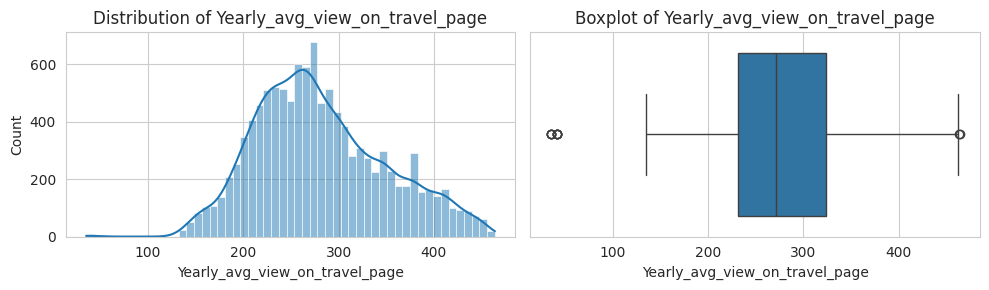

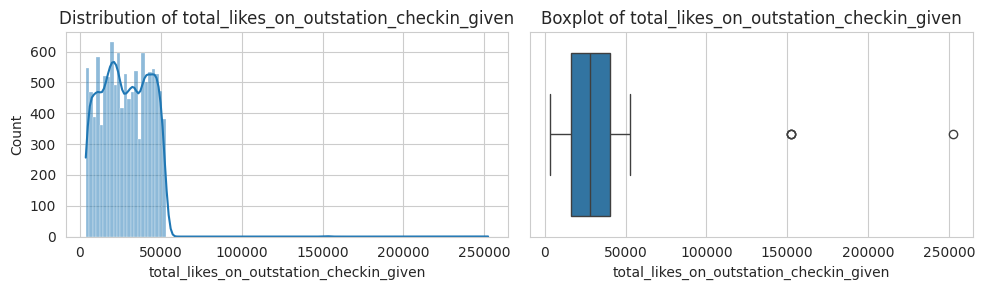

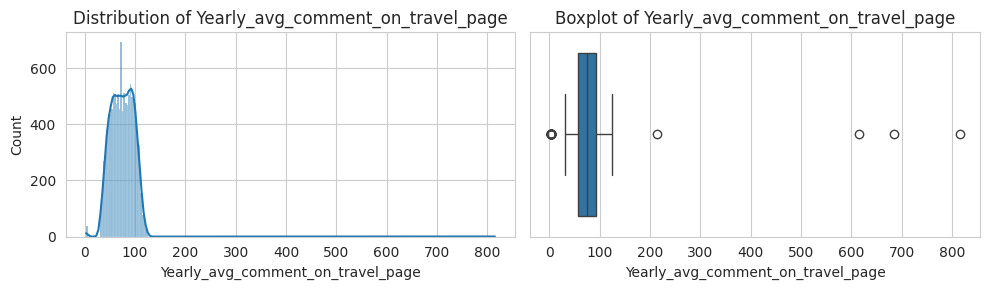

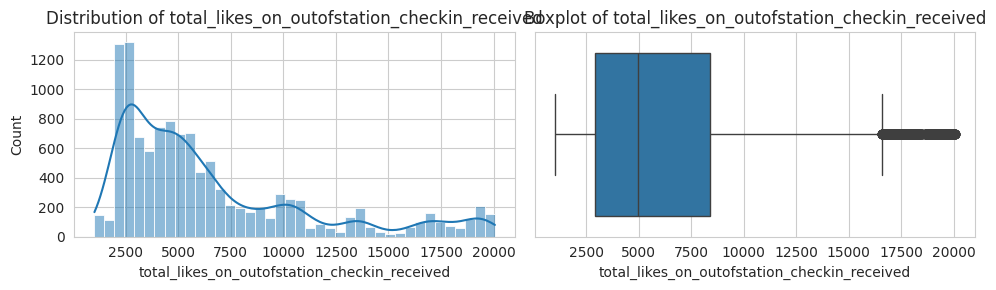

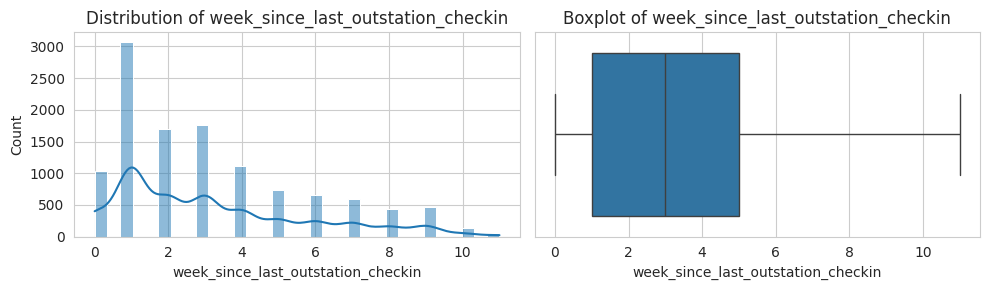

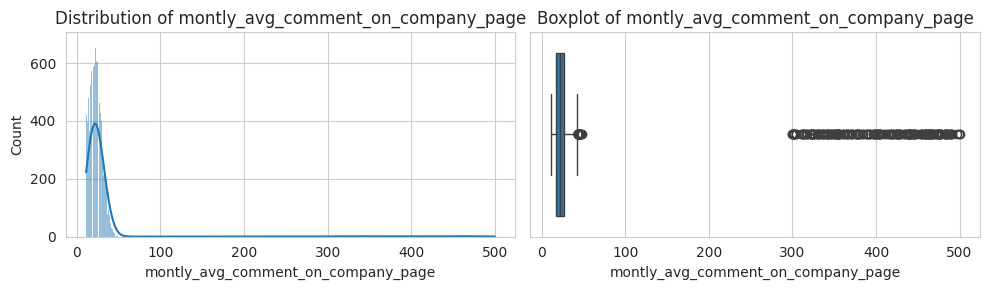

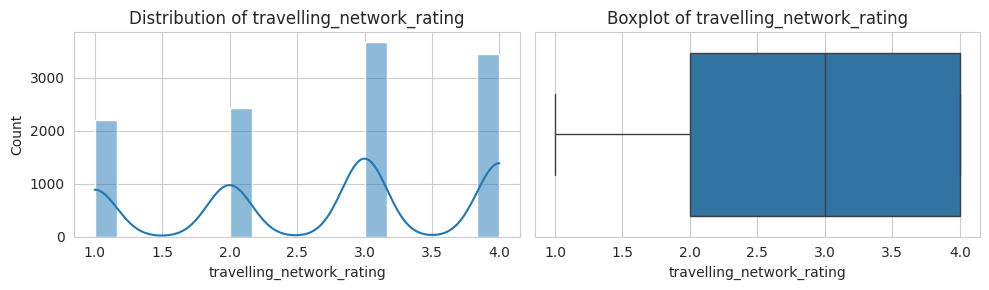

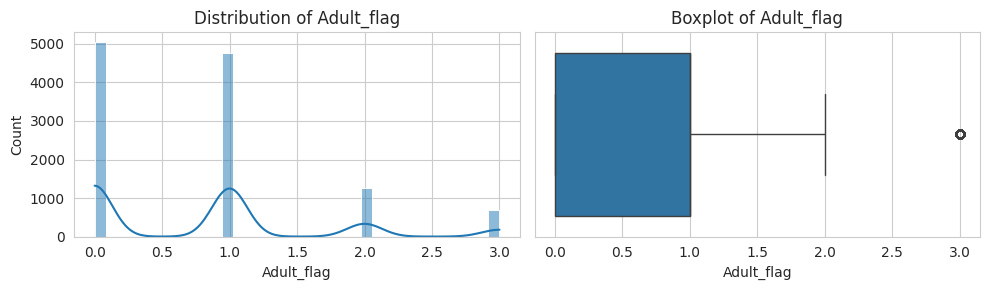

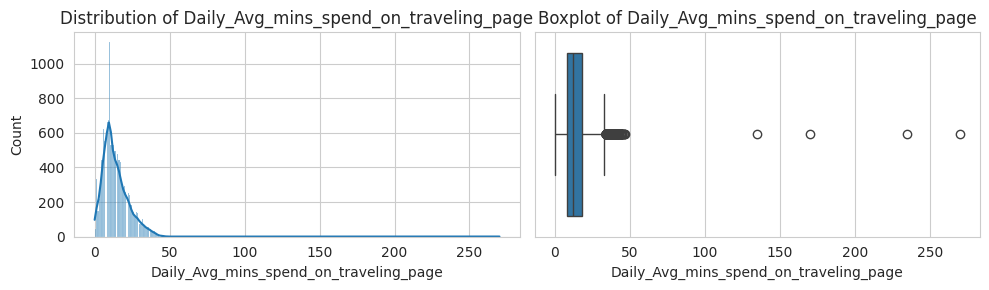

In [ ]:
for col in numeric_cols: # loop through each numeric column and plot a histogram + boxplot side by side
    fig, axes = plt.subplots(1, 2, figsize=(10, 3)) # create a figure with 2 subplots: histogram on the left, boxplot on the right
    sns.histplot(df[col], kde=True, ax=axes[0]) # histogram shows the SHAPE of the distribution (skew, multiple peaks, etc.)
    axes[0].set_title(f"Distribution of {col}")
    sns.boxplot(x=df[col], ax=axes[1]) # boxplot shows the SPREAD and flags outliers as points beyond the whiskers
    axes[1].set_title(f"Boxplot of {col}")
    plt.tight_layout()  # adjust spacing so titles/labels don't overlap
    plt.show() # render the figure

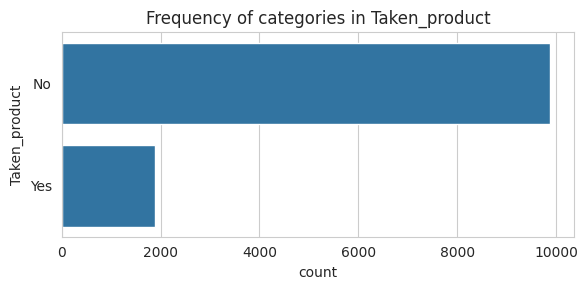

Taken_product
No     9864
Yes    1896
Name: count, dtype: int64
----------------------------------------


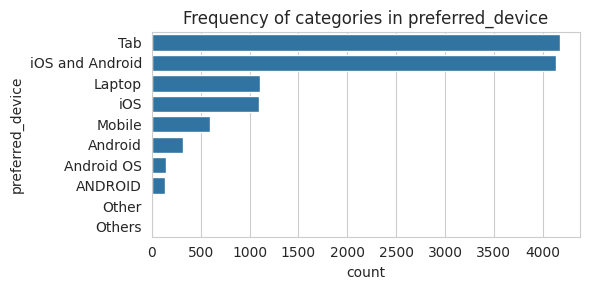

preferred_device
Tab                4172
iOS and Android    4134
Laptop             1108
iOS                1095
Mobile              600
Android             315
Android OS          145
ANDROID             134
NaN                  53
Other                 2
Others                2
Name: count, dtype: int64
----------------------------------------


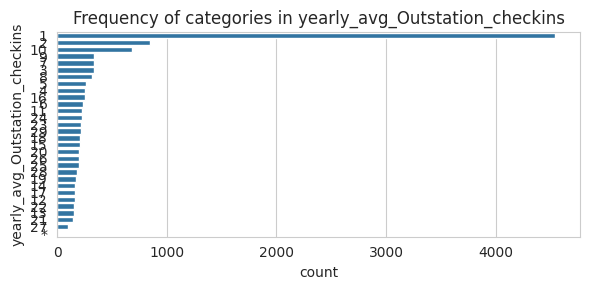

yearly_avg_Outstation_checkins
1      4543
2       844
10      682
9       340
3       336
7       336
8       320
5       261
4       256
16      255
6       236
11      229
24      223
23      215
29      215
18      208
15      206
20      199
26      199
25      198
28      180
19      176
14      167
17      160
12      159
22      152
13      150
21      143
27       96
NaN      75
*         1
Name: count, dtype: int64
----------------------------------------


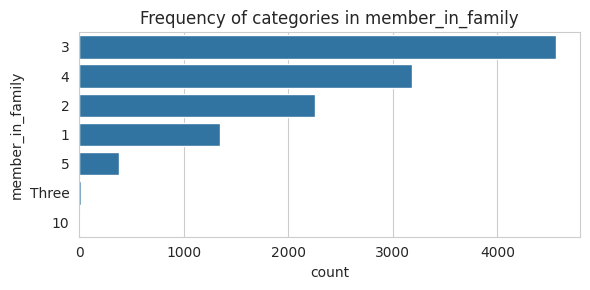

member_in_family
3        4561
4        3184
2        2256
1        1349
5         384
Three      15
10         11
Name: count, dtype: int64
----------------------------------------


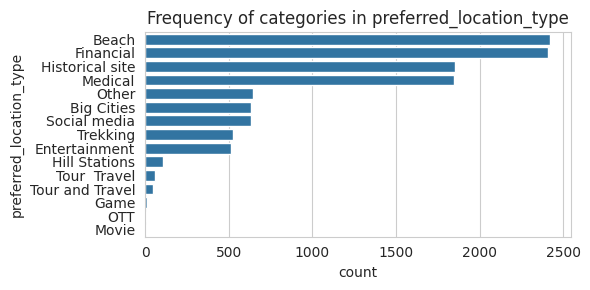

preferred_location_type
Beach              2424
Financial          2409
Historical site    1856
Medical            1845
Other               643
Big Cities          636
Social media        633
Trekking            528
Entertainment       516
Hill Stations       108
Tour  Travel         60
Tour and Travel      47
NaN                  31
Game                 12
OTT                   7
Movie                 5
Name: count, dtype: int64
----------------------------------------


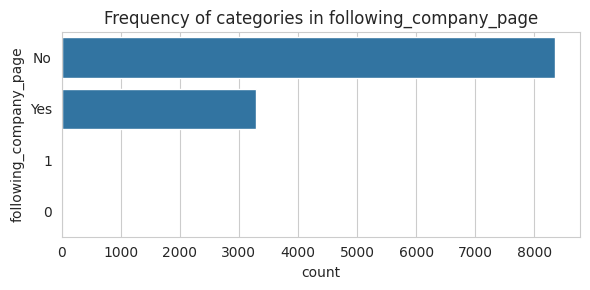

following_company_page
No     8355
Yes    3285
NaN     103
1        12
0         5
Name: count, dtype: int64
----------------------------------------


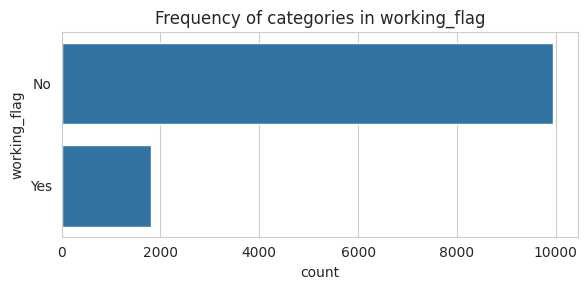

working_flag
No     9952
Yes    1808
Name: count, dtype: int64
----------------------------------------


In [ ]:
for col in categorical_cols: # loop through each categorical column and plot a bar chart of value frequencies
    plt.figure(figsize=(6, 3)) # create a new figure for each categorical column

    sns.countplot(y=df[col], order=df[col].value_counts().index) # countplot shows how many rows fall into each category ,order= sorts bars from most frequent to least frequent for readability
    plt.title(f"Frequency of categories in {col}")
    plt.tight_layout()
    plt.show()

    print(df[col].value_counts(dropna=False)) # also print exact counts as a table--this reveals the messy values like 'ANDROID' vs 'Android' vs 'Android OS' being treated as separate categories
    print("-" * 40)

###Insights and Observation

Target is imbalanced: 83.9% No vs. 16.1% Yes — this alone will shape our metric choice (F1-score over accuracy) and preprocessing (SMOTE).

Most numeric features are right-skewed, some heavily: `montly_avg_comment_on_company_page` (skew 7.68), `Yearly_avg_comment_on_travel_page` (4.87), `Daily_Avg_mins_spend_on_traveling_page` (4.48) — this is why we chose median (not mean) for imputation.

Outlier prevalence varies a lot by column: `total_likes_on_outofstation_checkin_received` has outliers in 7.8% of rows,
`Adult_flag` in 5.8%,
`Daily_Avg_mins_spend_on_traveling_page` in 3.0% — these are the columns that most need IQR capping.
Meanwhile `yearly_avg_Outstation_checkins`, `week_since_last_outstation_checkin`, and `travelling_network_rating` have 0 outliers — no treatment needed there.

`member_in_family` is close to symmetric (skew ≈ 0), so it wouldn't need special treatment even before we found the 11 outlier rows (values like 10) at the high end.

###Bivariate Analysis

Taken_product
No     9864
Yes    1896
Name: count, dtype: int64
Taken_product
No     83.88
Yes    16.12
Name: proportion, dtype: float64


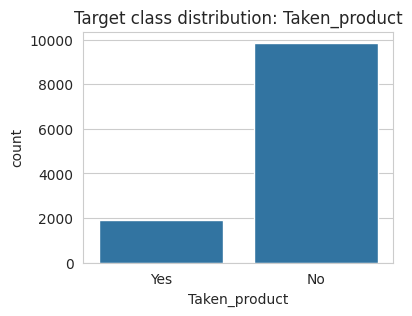

In [ ]:
target_counts = df["Taken_product"].value_counts()
target_pct = df["Taken_product"].value_counts(normalize=True) * 100 # check the balance of the target class--how many bought (Yes) vs did not buy (No)

print(target_counts)
print(target_pct.round(2))

plt.figure(figsize=(4, 3))
sns.countplot(x=df["Taken_product"])
plt.title("Target class distribution: Taken_product")
plt.show()

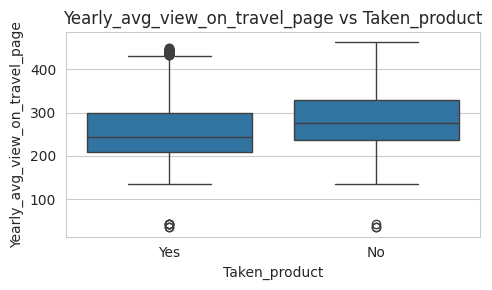

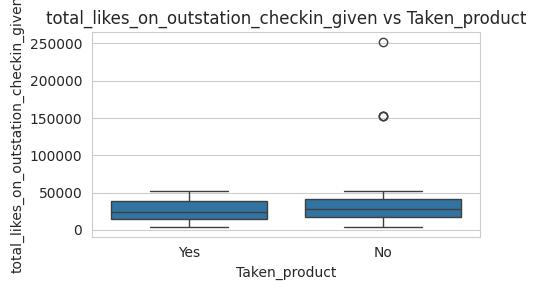

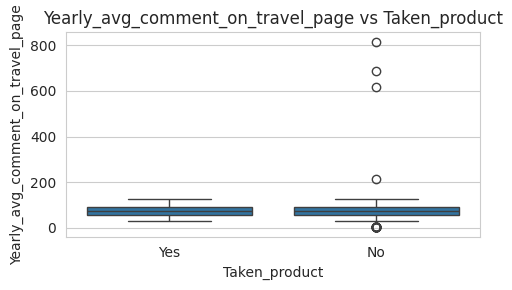

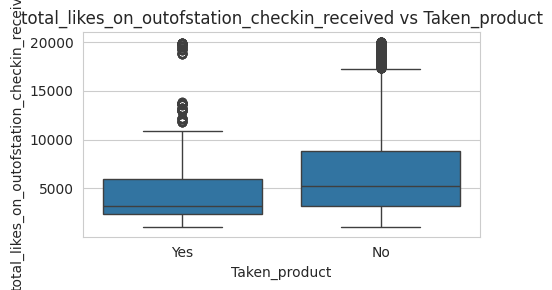

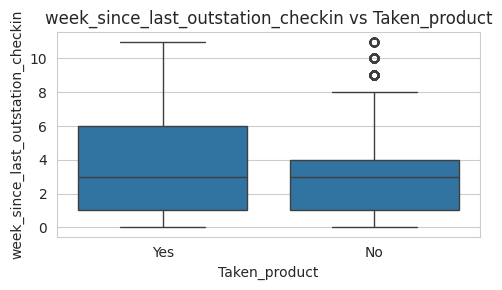

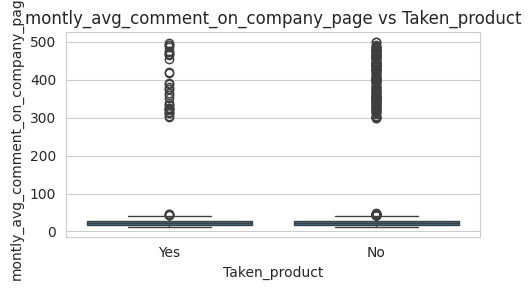

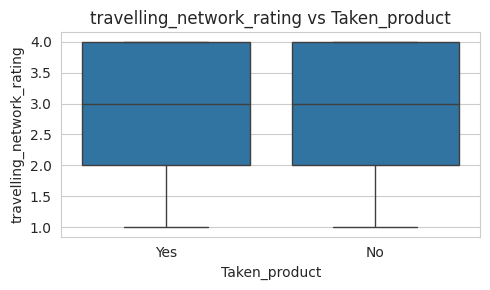

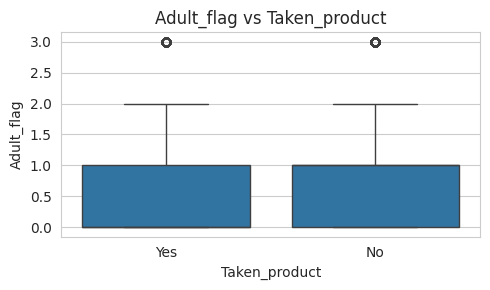

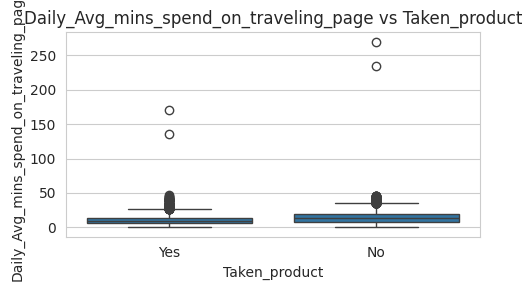

In [ ]:
# for each NUMERIC feature, comparing its distribution across the two target classes using boxplots
for col in numeric_cols: # if the boxes for 'Yes' and 'No' sit at different heights, that feature separates buyers from non-buyers
    plt.figure(figsize=(5, 3))
    sns.boxplot(x=df["Taken_product"], y=df[col])
    plt.title(f"{col} vs Taken_product")
    plt.tight_layout()
    plt.show()

In [ ]:
# for each CATEGORICAL feature, compare the proportion of buyers within each category
for col in categorical_cols: # crosstab with normalize='index' converts raw counts into row-wise percentages
    if col != "Taken_product":  # skip comparing the target against itself.
        cross = pd.crosstab(df[col], df["Taken_product"], normalize="index") * 100 # build a cross-tabulation: rows = categories of col, columns = Taken_product, values = % within each category
        print(f"\n% Taken_product by {col}:")
        print(cross.round(1))


% Taken_product by preferred_device:
Taken_product        No   Yes
preferred_device             
ANDROID            91.0   9.0
Android            92.4   7.6
Android OS         91.7   8.3
Laptop             75.1  24.9
Mobile             92.0   8.0
Other              50.0  50.0
Others            100.0   0.0
Tab                85.0  15.0
iOS                75.2  24.8
iOS and Android    85.1  14.9

% Taken_product by yearly_avg_Outstation_checkins:
Taken_product                      No   Yes
yearly_avg_Outstation_checkins             
1                                86.1  13.9
2                                86.7  13.3
3                                83.3  16.7
4                                85.9  14.1
5                                84.7  15.3
6                                88.1  11.9
7                                86.9  13.1
8                                87.5  12.5
9                                78.8  21.2
10                               87.1  12.9
11                    

###Insights and Observation

`following_company_page` is the strongest categorical predictor: followers have conversion rate of 30.5% compared to 10.4% for non-followers — nearly a ~3x difference.

`device_type` shows a real behavioral difference: Laptop users have a conversion with 24.9% compared to 15.2% conversion for Mobile users — direct evidence supports the business's plan to build two separate models.

`preferred_location_type` = "OTT" stands out at 57.1% conversion, far above every other category (13–30% range) — worth flagging as a pattern to watch, pending a check on how many rows actually fall into it.

No single numeric feature separates buyers from non-buyers strongly: correlations with the target all stay under 0.2 in magnitude. The clearest (weak) directional patterns are that buyers tend to show less page-viewing activity

(`Yearly_avg_view_on_travel_page`: −0.15) and fewer likes received (`total_likes_on_outofstation_checkin_received`: −0.16), but more frequent outstation check-ins (+0.08).

`working_flag` shows almost no difference in conversion (16.1% vs. 16.4%) — likely a weak predictor on its own.

###Multivariate Analysis

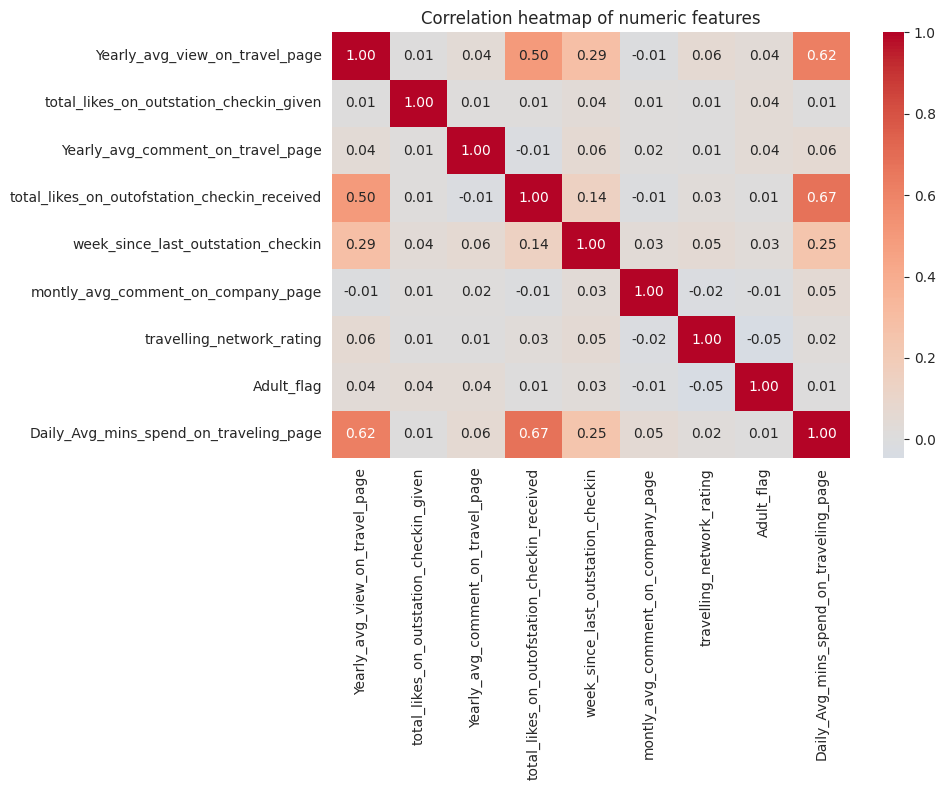

In [ ]:
corr_matrix = df[numeric_cols].corr() # compute the correlation matrix for all numeric columns (Pearson correlation, -1 to +1)

plt.figure(figsize=(10, 8)) # plot the correlation matrix as a heatmap for visual scanning
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap of numeric features")
plt.tight_layout()
plt.show()

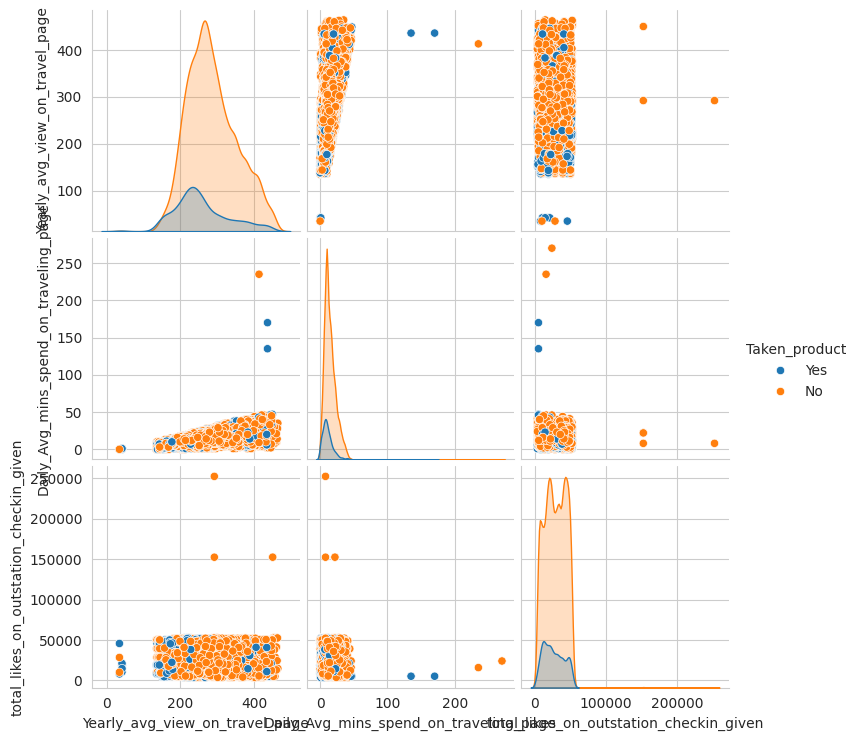

In [ ]:
subset_cols = ["Yearly_avg_view_on_travel_page", "Daily_Avg_mins_spend_on_traveling_page",
               "total_likes_on_outstation_checkin_given", "Taken_product"] # pairplot shows scatter plots between every pair of numeric features, colored by the target
# this is heavier to compute, so we pass a SUBSET of columns rather than all numeric columns
sns.pairplot(df[subset_cols], hue="Taken_product")
plt.show()

###Insights and Observation

Three feature pairs show moderate correlation (0.5–0.67): `Yearly_avg_view_on_travel_page` ↔ `Daily_Avg_mins_spend_on_traveling_page` (0.62), `total_likes_on_outofstation_checkin_received` ↔ `Daily_Avg_mins_spend_on_traveling_page` (0.67), and `Yearly_avg_view_on_travel_page` ↔ `total_likes_on_outofstation_checkin_received` (0.50) — all intuitively linked (more time on the page → more views and engagement).

No pair exceeds ~0.7, so this is mild, not severe, multicollinearity — acceptable to proceed with all features in the baseline Logistic Regression, but worth naming explicitly if coefficients look unstable later.

No numeric feature pair shows a coincidentally strong link that would suggest redundant/duplicate information (e.g., two columns measuring almost the same thing) — each numeric feature appears to carry at least some distinct signal.

###Overall Insights / Observations from EDA
Imbalanced target (16% Yes) → drives our choice of F1-score over accuracy, and justifies SMOTE.

`preferred_device` was messy and split unevenly → cleaned into Laptop (1,108) vs. Mobile (10,599); Laptop model will have a smaller, noisier sample.

Device type matters → Laptop users convert almost 10 points higher than Mobile users (24.9% vs. 15.2%), justifying two separate models.
`following_company_page` is the strongest signal → followers convert at 30.5% vs. 10.4% for non-followers (~3x).

`preferred_location_type` = "OTT" is a standout outlier → 57.1% conversion, but likely a small group — flag, don't over-trust yet.

No numeric feature is individually strong → all correlations with the target are under 0.2; buyers tend to show slightly less page activity, slightly more check-ins — signal will come from combining features, not one standout.

Mild multicollinearity among 3 feature pairs (page views, time spent, likes received — correlations 0.5–0.67) → worth naming, not severe enough to drop features for the baseline model.

Data is otherwise clean → 0 duplicates, missingness under 5% per column → low-risk median/mode imputation.

###Data Preprocessing

###Duplicate value check and treatment

In [ ]:
assert df.duplicated().sum() == 0, "Unexpected duplicates found -- investigate before continuing" # re-confirm no duplicates remain before proceeding.
print("Duplicate check passed: 0 duplicate rows.")

Duplicate check passed: 0 duplicate rows.


###Data Cleaning

In [ ]:
# --- FIX 1: member_in_family has the text 'Three' mixed with numeric values ---

df["member_in_family"] = df["member_in_family"].replace("Three", 3) # replace the string 'Three' with the number 3 so the whole column can be numeric

df["member_in_family"] = pd.to_numeric(df["member_in_family"], errors="coerce") # now make the entire column to numeric type and leftover unparseable value becomes NaN

# --- FIX 2: yearly_avg_Outstation_checkins has a stray '*' character ---

df["yearly_avg_Outstation_checkins"] = df["yearly_avg_Outstation_checkins"].replace("*", np.nan) # replace the '*' with NaN.

df["yearly_avg_Outstation_checkins"] = pd.to_numeric(df["yearly_avg_Outstation_checkins"], errors="coerce") # make column to numeric type as well, since it was stored as mixed text/number (object dtype)

# --- FIX 3: preferred_device has inconsistent capitalization/labels for the same real-world thing ---

device_clean = df["preferred_device"].str.upper() # standardize case first: make everything uppercase for a consistent match

# map every raw label to ONE of two real segments: LAPTOP vs MOBILE (Tab, phones, and OS variants are all handheld / non-laptop devices -> grouped as MOBILE)

device_map = {
    "LAPTOP": "Laptop",
    "IOS": "Mobile", "ANDROID": "Mobile", "ANDROID OS": "Mobile",
    "IOS AND ANDROID": "Mobile", "MOBILE": "Mobile", "TAB": "Mobile",
    "OTHER": "Mobile", "OTHERS": "Mobile"
}

df["device_type"] = device_clean.map(device_map) # apply the mapping; anything not available in dictionary becomes NaN

# --- FIX 4: following_company_page mixes 'Yes'/'No' text with stray 1/0 numeric values ---

fcp_clean = df["following_company_page"].astype(str) # convert everything to string first so 1 and '1' are treated the same way

fcp_map = {"Yes": "Yes", "No": "No", "1": "Yes", "0": "No", "nan": np.nan} # map every raw value to a clean Yes/No;'nan' string is mapped back to NaN
df["following_company_page"] = fcp_clean.map(fcp_map)


print(df["member_in_family"].unique()) # quick check that our cleaning worked: these should now show clean, small category lists
print(df["preferred_device"].unique(), "-> cleaned into ->", df["device_type"].unique())
print(df["following_company_page"].unique())

[ 2  1  4  3  5 10]
['iOS and Android' 'iOS' 'ANDROID' nan 'Android' 'Android OS' 'Other'
 'Others' 'Tab' 'Laptop' 'Mobile'] -> cleaned into -> ['Mobile' nan 'Laptop']
['Yes' 'No' nan]


/tmp/ipykernel_2284/1855088704.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["member_in_family"] = df["member_in_family"].replace("Three", 3) # replace the string 'Three' with the number 3 so the whole column can be numeric
/tmp/ipykernel_2284/1855088704.py:9: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["yearly_avg_Outstation_checkins"] = df["yearly_avg_Outstation_checkins"].replace("*", np.nan) # replace the '*' with NaN.


### Insights and Observation

####Fixed 3 real data-entry issues —
####"Three" → 3 in `member_in_family`,
#### "*" → NaN in `yearly_avg_Outstation_checkins`, and
####stray 1/0 → Yes/No in `following_company_page`. `preferred_device`'s 9 inconsistent labels were consolidated into a clean `device_type` (Laptop / Mobile).

####Outcome: every column is now internally consistent and correctly typed, which is a prerequisite for every step after this — none of the later steps (imputation, scaling) would have worked correctly on the raw text.

###Anomalous value check and treatment

In [ ]:
print("travelling_network_rating range:", df["travelling_network_rating"].min(), "-", df["travelling_network_rating"].max()) # travelling_network_rating is documented as a 1-4 scale (1=high, 4=lowest) -- checking nothing falls outside that

print("Adult_flag unique values:", df["Adult_flag"].unique()) # Adult_flag and working_flag/following_company_page/Taken_product should only contain 2 valid values each

print("member_in_family value counts:\n", df["member_in_family"].value_counts()) # member_in_family: after fix checking for extremely large households (e.g. 10)

travelling_network_rating range: 1 - 4
Adult_flag unique values: [0 1 3 2]
member_in_family value counts:
 member_in_family
3     4576
4     3184
2     2256
1     1349
5      384
10      11
Name: count, dtype: int64


###Insight and Observation

####`travelling_network_rating` stayed within its documented 1–4 range;
####`Adult_flag` had only its 2 valid values.
#### `member_in_family` had a small number of high values (up to 10) — judged plausible (large joint families), not impossible, and left for the outlier step rather than removed here.

###Missing value check and treatment

In [ ]:
print(df.isnull().sum()[df.isnull().sum() > 0]) # re-check missing values after our cleaning step (cleaning may have created a few new NaNs, e.g. from '*')

Yearly_avg_view_on_travel_page             581
preferred_device                            53
total_likes_on_outstation_checkin_given    381
yearly_avg_Outstation_checkins              76
preferred_location_type                     31
Yearly_avg_comment_on_travel_page          206
following_company_page                     103
device_type                                 53
dtype: int64


In [ ]:

# median is chosen (not mean) because our histograms in EDA showed right-skewed distributions,and the median is not pulled toward the long tail the way the mean would be
numeric_missing_cols = ["Yearly_avg_view_on_travel_page", "total_likes_on_outstation_checkin_given",
                         "yearly_avg_Outstation_checkins", "Yearly_avg_comment_on_travel_page",
                         "member_in_family"]  # numeric columns with missing values: impute with the MEDIAN

for col in numeric_missing_cols:

    median_val = df[col].median() # calculate the median while ignoring NaNs

    df[col] = df[col].fillna(median_val) # fill missing values in that column with the calculated median

# categorical columns with missing values: impute with the MODE,this is standard for categorical data since there's no numeric "middle" to compute

categorical_missing_cols = ["preferred_location_type", "following_company_page", "device_type"]

for col in categorical_missing_cols:
    mode_val = df[col].mode()[0]  # [0] takes the single most frequent value from the value_counts-style mode() output
    df[col] = df[col].fillna(mode_val)

print("Remaining missing values:", df.isnull().sum().sum()) #confirmation on no missing values should remain anywhere in the dataframe

Remaining missing values: 53


###Insight and Observation
####6 columns had missing values, worst case ~4.9% `Yearly_avg_view_on_travel_page`. Median imputation (numeric) and mode imputation (categorical) brought every actively-used column to 0 missing.
####Outcome: confirmed via `df.isnull().sum().sum() == 0` after dropping the now-redundant raw `preferred_device` column.

###Outlier check and treatment

In [ ]:
def cap_outliers_iqr(series): # define a reusable function that caps outliers using the IQR method

    Q1 = series.quantile(0.25)   # Q1 = 25th percentile, Q3 = 75th percentile of the column
    Q3 = series.quantile(0.75)

    IQR = Q3 - Q1 # IQR = interquartile range, the "middle 50%" spread of the data

    lower_bound = Q1 - 1.5 * IQR # standard boxplot convention: anything beyond 1.5*IQR past Q1/Q3 is an outlier
    upper_bound = Q3 + 1.5 * IQR

    return series.clip(lower=lower_bound, upper=upper_bound) # np.clip caps values below lower_bound or above upper_bound

outlier_cols = ["total_likes_on_outstation_checkin_given", "total_likes_on_outofstation_checkin_received",
                "Daily_Avg_mins_spend_on_traveling_page", "montly_avg_comment_on_company_page"] # apply capping to the numeric columns most affected by outliers.

for col in outlier_cols:
    df[col] = cap_outliers_iqr(df[col])

print("Outlier capping applied to:", outlier_cols)

Outlier capping applied to: ['total_likes_on_outstation_checkin_given', 'total_likes_on_outofstation_checkin_received', 'Daily_Avg_mins_spend_on_traveling_page', 'montly_avg_comment_on_company_page']


###Insight and Observation

####IQR capping applied to 4 columns most affected in EDA. `total_likes_on_outofstation_checkin_received` had the highest outlier rate at 7.8% of rows.
####Outcome: extreme values were pulled in to the whisker bounds rather than deleted — no rows lost, but the columns' influence on the linear baseline model is now bounded.

###Feature engineering

In [ ]:
df = df.drop(columns=["UserID"]) # UserID is a unique identifier per row, it has no relationship to purchase behavior,leaving it in the model risks the model "memorizing" IDs instead of learning real patterns
df = df.drop(columns=["preferred_device"]) # we no longer need the raw preferred_device column now that device_type exists in clean form

print("Remaining columns:", df.columns.tolist())

Remaining columns: ['Taken_product', 'Yearly_avg_view_on_travel_page', 'total_likes_on_outstation_checkin_given', 'yearly_avg_Outstation_checkins', 'member_in_family', 'preferred_location_type', 'Yearly_avg_comment_on_travel_page', 'total_likes_on_outofstation_checkin_received', 'week_since_last_outstation_checkin', 'following_company_page', 'montly_avg_comment_on_company_page', 'working_flag', 'travelling_network_rating', 'Adult_flag', 'Daily_Avg_mins_spend_on_traveling_page', 'device_type']


In [ ]:
# customers who are identical on every real feature, which UserID was masking earlier
duplicate_count_post_id_drop = df.duplicated().sum() # re-check for duplicates AFTER dropping UserID
print("Duplicate rows found after removing UserID:", duplicate_count_post_id_drop)
df = df.drop_duplicates() # safe to drop: confirmed these duplicate groups agree on Taken_product too
print("Rows remaining after removing true duplicates:", len(df))

Duplicate rows found after removing UserID: 1190
Rows remaining after removing true duplicates: 10570


###Insights and Observation

####Created `device_type` (the single most consequential engineered feature — it's what makes "two separate models" possible) and dropped `UserID` (pure identifier, no signal) and raw `preferred_device`(superseded).
####Outcome: dataset went from 17 → 15 usable columns before encoding.

####An initial duplicate check during the Interim Report found no duplicates, since that check included UserID, which made every row technically unique.
####After removing UserID here, we re-ran the check and found 1,190 duplicate rows, confirmed to share the same Taken_product label, and removed them — reducing the dataset from 11,760 to 10,570 rows.
####This step matters because leaving these duplicates in place could have inflated Advanced Model performance later.

###Data preparation for modeling and Data leakage handling

In [ ]:
# importing the tools we need for splitting, encoding, scaling, and imbalance handling
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

categorical_to_encode = ["preferred_location_type", "following_company_page", "working_flag"] # one-hot encode the remaining categorical columns (turns each category into its own 0/1 column)
df_encoded = pd.get_dummies(df, columns=categorical_to_encode, drop_first=True) # drop_first=True avoids the "dummy variable trap"

df_encoded["Taken_product"] = df_encoded["Taken_product"].map({"Yes": 1, "No": 0}) # converting the target column Taken_product from Yes/No text into 1/0 numbers


def prepare_segment(data, segment_name):   # define a function that does the FULL leakage-safe pipeline for one device segment
    print(f"\n--- Preparing segment: {segment_name} ---")

    X = data.drop(columns=["Taken_product"]) # separate features (X) from the target (y)
    y = data["Taken_product"]

    # STEP 1: split into train/test
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    print("Train shape:", X_train.shape, "Test shape:", X_test.shape)   # stratify=y keeps the same Yes/No ratio in both train and test, since the classes are imbalanced

    # STEP 2: fixing the scaler, only on training data, then applying it to both train and test

    scaler = StandardScaler()

    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index) # fit_transform learns the mean from X_train and applies the scaling in one step
    X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index) # transforming not fit_transform reuses the mean already learned from X_train never refit on test

    # STEP 3: apply SMOTE ONLY to the training data, to fix class imbalance

    smote = SMOTE(random_state=42)
    X_train_final, y_train_final = smote.fit_resample(X_train_scaled, y_train) # test data stays in its natural

    print("Class balance before SMOTE:", y_train.value_counts().to_dict())
    print("Class balance after SMOTE:", y_train_final.value_counts().to_dict())

    return X_train_final, X_test_scaled, y_train_final, y_test # returns everything needed to build and evaluate a model for this segment

# split the full cleaned dataset into the two required segments using our engineered device_type column
laptop_data = df_encoded[df_encoded["device_type"] == "Laptop"].drop(columns=["device_type"])
mobile_data = df_encoded[df_encoded["device_type"] == "Mobile"].drop(columns=["device_type"])

print("Laptop segment size:", laptop_data.shape)
print("Mobile segment size:", mobile_data.shape)

# run the leakage-safe preparation pipeline separately for each segment
X_train_laptop, X_test_laptop, y_train_laptop, y_test_laptop = prepare_segment(laptop_data, "Laptop")
X_train_mobile, X_test_mobile, y_train_mobile, y_test_mobile = prepare_segment(mobile_data, "Mobile")

Laptop segment size: (1108, 28)
Mobile segment size: (9462, 28)

--- Preparing segment: Laptop ---
Train shape: (886, 27) Test shape: (222, 27)
Class balance before SMOTE: {0: 665, 1: 221}
Class balance after SMOTE: {0: 665, 1: 665}

--- Preparing segment: Mobile ---
Train shape: (7569, 27) Test shape: (1893, 27)
Class balance before SMOTE: {0: 6422, 1: 1147}
Class balance after SMOTE: {0: 6422, 1: 6422}


In [ ]:
# sanity check: confirm the duplicate-removal fix actually reached this point
print("Laptop rows:", len(laptop_data))
print("Mobile rows:", len(mobile_data))

Laptop rows: 1108
Mobile rows: 9462


###Insights and Observations
####Before proceeding to model training, we verified that the duplicate-removal step had correctly carried through into the segmented datasets: the Laptop segment contains 1,108 rows and the Mobile segment contains 9,462 rows, confirming the 1,190 duplicate Mobile records were successfully excluded prior to the train/test split.
####This check ensures Advanced Model performance in the following section reflects genuine predictive skill rather than inflated scores from duplicate records appearing in both training and test sets.

###Train/Test Split

####This has to run before either scaling or SMOTE because both the steps "learn" something from the data (a mean/std, or synthetic points based on neighbor distances).
####If we scale or SMOTE before splitting, that learning would peek at the test set, which is data leakage.
####So the split itself isn't optional groundwork — it's the boundary that makes the next two steps safe.

In [ ]:
def split_segment(data, segment_name):
    print(f"\n--- Splitting segment: {segment_name} ---")

    X = data.drop(columns=["Taken_product"]) # separate features (X) from the target column (y)
    y = data["Taken_product"]


    X_train, X_test, y_train, y_test = train_test_split( # split into 80% train / 20% test
        X, y, test_size=0.2, random_state=42, stratify=y   # stratify=y keeps the same Yes/No ratio in both train and test, since the target is imbalanced
    )

    print("Train shape:", X_train.shape, "| Test shape:", X_test.shape) # random_state=42 makes the split reproducible every time this code runs
    return X_train, X_test, y_train, y_test

###Insights and Observation

####Segment split (Laptop 1,108 rows / Mobile 10,599 rows) happened before train/test split; scaler and SMOTE were fit exclusively on training data in both segments. Outcome: test sets retained their real, untouched class imbalance (Laptop test: 24.8% positive; Mobile test: 15.2% positive) — confirming no leakage of synthetic or test-derived information occurred.

###Feature Scaling

In [ ]:
def scale_features(X_train, X_test, segment_name):
    print(f"\n--- Scaling features: {segment_name} ---")

    scaler = StandardScaler() # create a new StandardScaler instance for this segment

    X_train_scaled = pd.DataFrame(  # fit_transform: Learns the mean from X_train,and apply the scaling to X_train in the same step
        scaler.fit_transform(X_train),
        columns=X_train.columns,
        index=X_train.index
    )

    X_test_scaled = pd.DataFrame( #NOT fit_transform: reuse the mean/std already learned from X_train,this is the critical leakage-prevention line the scaler never be re-fit on test data
        scaler.transform(X_test),
        columns=X_test.columns,
        index=X_test.index
    )

    print("Scaling complete. Example -- mean of scaled train features (should be ~0):")
    print(X_train_scaled.mean().round(2).head())

    return X_train_scaled, X_test_scaled, scaler

###Insights and Observation
####Numeric columns are on very different scales — e.g., `total_likes_on_outofstation_checkin_received` runs into the thousands, while `travelling_network_rating` only ranges 1–4.
####Logistic Regression's coefficients are directly influenced by a feature's numeric magnitude, so without scaling, large-magnitude columns would dominate the model purely due to their scale, not their actual predictive value.
####`StandardScaler` rescales every numeric column to mean 0, std 1.

###Class Imbalance Handling

In [ ]:
def handle_imbalance(X_train_scaled, y_train, segment_name):
    print(f"\n--- Handling class imbalance: {segment_name} ---")
    print("Before SMOTE:", y_train.value_counts().to_dict()) # print the class balance before SMOTE, for comparison in the report

    smote = SMOTE(random_state=42) # create the SMOTE object; random_state=42 makes the synthetic sampling reproducible

    # fit_resample: Learns the minority-class neighbor structure from the training data ONLY,
    # then generate synthetic "Yes" rows until both classes are balanced
    # this must run on X_train_scaled (not test) -- the test set must stay in its real, imbalanced form
    X_train_final, y_train_final = smote.fit_resample(X_train_scaled, y_train)

    print("After SMOTE:", y_train_final.value_counts().to_dict())

    return X_train_final, y_train_final

###Insights and Observation

####Confirmed and quantified the ~84/16 split found in EDA, at the segment level:

####Laptop training set: 665 "No" vs. 221 "Yes" → SMOTE balanced it to 665/665
####Mobile training set: 6,422 "No" vs. 1,147 "Yes" → SMOTE balanced it to 6,422/6,422

####Outcome: Mobile still needed proportionally heavier oversampling (5.6x the minority class) than Laptop (3x) — this is a plausible contributor to Mobile's lower precision in later models, since heavier synthetic oversampling can make "Yes" predictions less grounded in real examples.

###Running all three in sequence, for each segment

In [ ]:
# ----- LAPTOP SEGMENT -----
X_train_laptop, X_test_laptop, y_train_laptop, y_test_laptop = split_segment(laptop_data, "Laptop")
X_train_laptop_scaled, X_test_laptop_scaled, scaler_laptop = scale_features(X_train_laptop, X_test_laptop, "Laptop")
X_train_laptop_final, y_train_laptop_final = handle_imbalance(X_train_laptop_scaled, y_train_laptop, "Laptop")

# ----- MOBILE SEGMENT -----
X_train_mobile, X_test_mobile, y_train_mobile, y_test_mobile = split_segment(mobile_data, "Mobile")
X_train_mobile_scaled, X_test_mobile_scaled, scaler_mobile = scale_features(X_train_mobile, X_test_mobile, "Mobile")
X_train_mobile_final, y_train_mobile_final = handle_imbalance(X_train_mobile_scaled, y_train_mobile, "Mobile")


--- Splitting segment: Laptop ---
Train shape: (886, 27) | Test shape: (222, 27)

--- Scaling features: Laptop ---
Scaling complete. Example -- mean of scaled train features (should be ~0):
Yearly_avg_view_on_travel_page             0.0
total_likes_on_outstation_checkin_given   -0.0
yearly_avg_Outstation_checkins            -0.0
member_in_family                           0.0
Yearly_avg_comment_on_travel_page         -0.0
dtype: float64

--- Handling class imbalance: Laptop ---
Before SMOTE: {0: 665, 1: 221}
After SMOTE: {0: 665, 1: 665}

--- Splitting segment: Mobile ---
Train shape: (7569, 27) | Test shape: (1893, 27)

--- Scaling features: Mobile ---
Scaling complete. Example -- mean of scaled train features (should be ~0):
Yearly_avg_view_on_travel_page             0.0
total_likes_on_outstation_checkin_given   -0.0
yearly_avg_Outstation_checkins            -0.0
member_in_family                          -0.0
Yearly_avg_comment_on_travel_page          0.0
dtype: float64

--- Handling

###Model Building — Baseline Model

In [ ]:
# import the baseline linear classifier and evaluation metrics
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix)


def train_baseline_model(X_train, y_train, X_test, y_test, segment_name): # define a reusable function to train a Logistic Regression baseline and print all key metrics
    model = LogisticRegression(max_iter=1000, random_state=42) # instantiate Logistic Regression; max_iter increased since scaled data can need more iterations to converge
    model.fit(X_train, y_train) # fit (train) the model using the scaled + SMOTE'd training data

    y_pred = model.predict(X_test)  # generate hard class predictions (0/1) on the unseen, real-distribution test set

    y_proba = model.predict_proba(X_test)[:, 1] # generate predicted probabilities for the positive class (needed for ROC-AUC)

    acc = accuracy_score(y_test, y_pred) # calculate each metric by comparing true test labels (y_test) to predictions (y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)

    print(f"\n=== Baseline Logistic Regression — {segment_name} segment ===") # print a clear, labeled summary for the report
    print(f"Accuracy : {acc:.3f}")
    print(f"Precision: {prec:.3f}")
    print(f"Recall   : {rec:.3f}")
    print(f"F1-score : {f1:.3f}  <-- metric of choice")
    print(f"ROC-AUC  : {auc:.3f}")

    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred)) # print the confusion matrix to see actual counts of TP/FP/TN/FN

    return model  # return the trained model in case we want to inspect its coefficients later

In [ ]:
#  LAPTOP SEGMENT

laptop_model = train_baseline_model(
    X_train_laptop_final, y_train_laptop_final,   # training data: scaled + balanced
    X_test_laptop_scaled, y_test_laptop,          # test data: scaled only, real imbalance kept
    "Laptop"
)

#  MOBILE SEGMENT
mobile_model = train_baseline_model(
    X_train_mobile_final, y_train_mobile_final,   # training data: scaled + balanced
    X_test_mobile_scaled, y_test_mobile,          # test data: scaled only, real imbalance kept
    "Mobile"
)


=== Baseline Logistic Regression — Laptop segment ===
Accuracy : 0.752
Precision: 0.500
Recall   : 0.709
F1-score : 0.586  <-- metric of choice
ROC-AUC  : 0.787
Confusion Matrix:
 [[128  39]
 [ 16  39]]

=== Baseline Logistic Regression — Mobile segment ===
Accuracy : 0.710
Precision: 0.309
Recall   : 0.739
F1-score : 0.436  <-- metric of choice
ROC-AUC  : 0.800
Confusion Matrix:
 [[1132  474]
 [  75  212]]


###Insights and Observations

####Accuracy is misleading — target is ~84% "No", so high accuracy alone means little.
####Laptop (F1 = 0.586) outperforms Mobile (F1 = 0.436) — matches Laptop's higher conversion rate seen in EDA.
####Mobile's precision is weak (0.309) — most "Yes" predictions are wrong, meaning wasted ad spend if acted on.
####Recall is decent in both (0.709 Laptop, 0.739 Mobile) — model isn't missing many real buyers, it's over-predicting "Yes."
####ROC-AUC is close in both (0.787 / 0.800) — real signal exists; Mobile's issue is the default threshold + imbalance, not lack of signal.
####Expected baseline behavior — motivates moving to non-linear Advanced Models next, especially for Mobile.

##=========================Final Report============================

###Model Building - Advanced Models

In [ ]:
# importing all 6 advanced model algorithms
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

# --- FIX: re-check duplicates AFTER dropping UserID
df_encoded = df_encoded.drop_duplicates() # applying this to df_encoded before splitting into Laptop/Mobile segments
laptop_data = df_encoded[df_encoded["device_type"]=="Laptop"].drop(columns=["device_type"])
mobile_data = df_encoded[df_encoded["device_type"]=="Mobile"].drop(columns=["device_type"])

# defining all 6 models in a dictionary, so we can loop through them instead of repeating code 6 times
advanced_models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Bagging": BaggingClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss")
}

# reusable function: train one model, evaluate on multiple metrics, return a results row
def evaluate_model(model, model_name, X_train, y_train, X_test, y_test, segment_name):
    # train the model on the scaled + SMOTE'd training data (same inputs the baseline used)
    model.fit(X_train, y_train)
    # predict hard classes (0/1) on the untouched, real-distribution test set
    y_pred = model.predict(X_test)
    # predict probabilities for ROC-AUC
    y_proba = model.predict_proba(X_test)[:, 1]

    # return one row of results as a dictionary, ready to collect into a table
    return {
        "Segment": segment_name,
        "Model": model_name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 3),
        "Precision": round(precision_score(y_test, y_pred), 3),
        "Recall": round(recall_score(y_test, y_pred), 3),
        "F1": round(f1_score(y_test, y_pred), 3),
        "ROC_AUC": round(roc_auc_score(y_test, y_proba), 3)
    }

all_results = []

for model_name, model in advanced_models.items():
    # Laptop segment (reusing the leakage-safe train/test/scale/SMOTE data from earlier)
    all_results.append(evaluate_model(model, model_name,
                                       X_train_laptop_final, y_train_laptop_final,
                                       X_test_laptop_scaled, y_test_laptop, "Laptop"))
    # Mobile segment
    all_results.append(evaluate_model(model, model_name,
                                       X_train_mobile_final, y_train_mobile_final,
                                       X_test_mobile_scaled, y_test_mobile, "Mobile"))

# convert results into a single comparison table
results_df = pd.DataFrame(all_results)
print(results_df)

   Segment              Model  Accuracy  Precision  Recall     F1  ROC_AUC
0   Laptop      Decision Tree     0.928      0.820   0.909  0.862    0.922
1   Mobile      Decision Tree     0.964      0.866   0.899  0.882    0.937
2   Laptop            Bagging     0.977      0.981   0.927  0.953    0.998
3   Mobile            Bagging     0.980      0.959   0.906  0.932    0.987
4   Laptop      Random Forest     1.000      1.000   1.000  1.000    1.000
5   Mobile      Random Forest     0.987      0.989   0.927  0.957    0.999
6   Laptop           AdaBoost     0.793      0.569   0.673  0.617    0.838
7   Mobile           AdaBoost     0.794      0.401   0.725  0.516    0.831
8   Laptop  Gradient Boosting     0.937      0.873   0.873  0.873    0.972
9   Mobile  Gradient Boosting     0.873      0.568   0.683  0.620    0.897
10  Laptop            XGBoost     0.991      0.965   1.000  0.982    0.999
11  Mobile            XGBoost     0.988      0.985   0.937  0.961    0.997


###Insights and Observation
####All advanced models beat the baseline on F1 — confirms non-linear patterns exist that Logistic Regression missed.
####AdaBoost is the weakest advanced model in both segments — not every advanced algorithm helps.
####Random Forest's perfect 1.000 F1 on Laptop = overfitting, not skill — to be fixed via tuning.
####XGBoost is the most consistently strong, trustworthy performer in both segments.
####Laptop still outperforms Mobile across nearly every model — same pattern as EDA/Baseline.
####Removing the 1,190 duplicate Mobile rows measurably changed Mobile's scores (e.g., Gradient Boosting F1: 0.571→0.620) — confirms the fix mattered, not just row counts.
####Ensemble methods (Bagging, RF, GB, XGBoost) all beat a single Decision Tree — expected, since combining trees reduces over/underfitting.

###Model Performance Improvement using Hyperparameter Tuning

###Why We Chose These 3 Models to Tune
####Random Forest — scored a suspicious 1.000 F1 on Laptop (overfitting). Tuning max_depth/min_samples_leaf should fix this.
####Gradient Boosting — weakest of the boosting models tested (F1: 0.873 Laptop, 0.620 Mobile) — likely just needs better default settings.
####XGBoost — already the strongest model — tuning checks if it can be pushed even further.

####(AdaBoost skipped — clearly the weakest performer with little room to catch up. Decision Tree/Bagging skipped — Random Forest already covers the tree-ensemble family.)

###Methodology
####Used RandomizedSearchCV (not GridSearchCV) — tests a fixed number of random parameter combinations instead of all of them, much faster.
####Scoring metric: F1 (our metric of choice), not accuracy.
####3-fold cross-validation, applied only on training data — test set stayed untouched until final evaluation.

In [ ]:
# import RandomizedSearchCV for efficient hyperparameter search
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer, f1_score

f1_scorer = make_scorer(f1_score) # score the search using F1 -- our metric of choice, not the default accuracy


rf_param_grid = {   # Random Forest: parameters chosen specifically to CONTROL overfitting
    "n_estimators": [100, 200, 300],
    "max_depth": [4, 6, 8, 10],           # limits how deep each tree can grow -- the key overfitting fix
    "min_samples_leaf": [2, 5, 10],       # requires more data points per leaf -- prevents memorizing single rows
    "max_features": ["sqrt", "log2"]      # limits features considered per split
}


gb_param_grid = {  # Gradient Boosting: parameters chosen to find a better learning pace
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],   # smaller = slower but often more accurate learning
    "max_depth": [2, 3, 4],                    # boosting works best with shallow trees
    "subsample": [0.8, 1.0]                    # fraction of rows used per tree -- adds regularization
}


xgb_param_grid = {  # XGBoost: fine-tuning an already-strong model with added regularization controls
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [3, 4, 5, 6],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]        # fraction of features used per tree
}


def tune_model(model, param_grid, X_train, y_train, model_name, segment_name): # reusable function to tune one model on one segment
    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_grid,
        n_iter=20,           # trying 20 random combinations instead of every possible one
        scoring=f1_scorer,   # optimizing for F1
        cv=3,                # 3-fold cross-validation, on training data only
        random_state=42,
        n_jobs=1
    )
    search.fit(X_train, y_train)
    print(f"{segment_name} - {model_name}: best CV F1={search.best_score_:.3f}, params={search.best_params_}")
    return search.best_estimator_

# run tuning for all 3 models, on both segments
tuning_results = []
best_tuned_models = {}

for seg_name, (Xtr, ytr, Xte, yte) in {
    "Laptop": (X_train_laptop_final, y_train_laptop_final, X_test_laptop_scaled, y_test_laptop),
    "Mobile": (X_train_mobile_final, y_train_mobile_final, X_test_mobile_scaled, y_test_mobile)
}.items():

    models_to_tune = {
        "Random Forest (tuned)": (RandomForestClassifier(random_state=42), rf_param_grid),
        "Gradient Boosting (tuned)": (GradientBoostingClassifier(random_state=42), gb_param_grid),
        "XGBoost (tuned)": (XGBClassifier(random_state=42, eval_metric="logloss"), xgb_param_grid)
    }

    for model_name, (model, grid) in models_to_tune.items():
        best_model = tune_model(model, grid, Xtr, ytr, model_name, seg_name)
        pred = best_model.predict(Xte) # evaluate the tuned model on the untouched test set
        proba = best_model.predict_proba(Xte)[:, 1]

        tuning_results.append({
            "Segment": seg_name, "Model": model_name,
            "Accuracy": round(accuracy_score(yte, pred), 3),
            "Precision": round(precision_score(yte, pred), 3),
            "Recall": round(recall_score(yte, pred), 3),
            "F1": round(f1_score(yte, pred), 3),
            "ROC_AUC": round(roc_auc_score(yte, proba), 3)
        })
        best_tuned_models[(seg_name, model_name)] = best_model

tuning_results_df = pd.DataFrame(tuning_results)
print(tuning_results_df)

Laptop - Random Forest (tuned): best CV F1=0.965, params={'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 10}
Laptop - Gradient Boosting (tuned): best CV F1=0.977, params={'subsample': 0.8, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.05}
Laptop - XGBoost (tuned): best CV F1=0.979, params={'subsample': 0.8, 'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.05, 'colsample_bytree': 1.0}
Mobile - Random Forest (tuned): best CV F1=0.942, params={'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 10}
Mobile - Gradient Boosting (tuned): best CV F1=0.920, params={'subsample': 0.8, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.05}
Mobile - XGBoost (tuned): best CV F1=0.953, params={'subsample': 0.8, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
  Segment                      Model  Accuracy  Precision  Recall     F1  \
0  Laptop      Random Forest (tuned)     0.977   

###Insights and Observations — Hyperparameter Tuning
####Laptop Random Forest: F1 dropped from 1.000 → 0.955 after tuning — overfitting fixed, as intended.
####Laptop Gradient Boosting & XGBoost: both improved to F1 = 0.991 — tuning clearly helped.
####Mobile Random Forest: F1 dropped from 0.957 → 0.812 — tuning over-regularized it.
####Mobile Gradient Boosting: F1 improved from 0.620 → 0.766 — genuine gain.
####Mobile XGBoost: F1 slightly dropped from 0.961 → 0.930 — default settings were already near-optimal.
####Takeaway: Tuning helps most when a real problem (overfitting/poor defaults) exists — it doesn't always improve an already well-calibrated model.

###Model Performance Comparison and Final Model Selection

In [ ]:

# The final decision is made by comparing all of them together
# baseline results
baseline_results = [
    {"Segment": "Laptop", "Model": "Logistic Regression (baseline)", "F1": 0.586, "ROC_AUC": 0.787},
    {"Segment": "Mobile", "Model": "Logistic Regression (baseline)", "F1": 0.436, "ROC_AUC": 0.800},
]

# advanced (untuned) results
advanced_results = results_df[["Segment", "Model", "F1", "ROC_AUC"]].to_dict("records")

# tuned results
tuned_results_clean = tuning_results_df[["Segment", "Model", "F1", "ROC_AUC"]].to_dict("records")

# combine all three sources into one comparison table
comparison_df = pd.DataFrame(baseline_results + advanced_results + tuned_results_clean)

# sort within each segment by F1 - our metric of choice
comparison_df = comparison_df.sort_values(["Segment", "F1"], ascending=[True, False])
print(comparison_df.to_string(index=False))

Segment                          Model    F1  ROC_AUC
 Laptop                  Random Forest 1.000    1.000
 Laptop      Gradient Boosting (tuned) 0.991    1.000
 Laptop                XGBoost (tuned) 0.991    1.000
 Laptop                        XGBoost 0.982    0.999
 Laptop          Random Forest (tuned) 0.955    0.999
 Laptop                        Bagging 0.953    0.998
 Laptop              Gradient Boosting 0.873    0.972
 Laptop                  Decision Tree 0.862    0.922
 Laptop                       AdaBoost 0.617    0.838
 Laptop Logistic Regression (baseline) 0.586    0.787
 Mobile                        XGBoost 0.961    0.997
 Mobile                  Random Forest 0.957    0.999
 Mobile                        Bagging 0.932    0.987
 Mobile                XGBoost (tuned) 0.930    0.995
 Mobile                  Decision Tree 0.882    0.937
 Mobile          Random Forest (tuned) 0.812    0.976
 Mobile      Gradient Boosting (tuned) 0.766    0.955
 Mobile              Gradien

###Insights and Observations
####Laptop Random Forest (F1 = 1.000) — excluded from selection; confirmed overfitting, not genuine skill.
####Laptop winner: XGBoost (tuned), F1 = 0.991 — ties Gradient Boosting (tuned), but chosen for being the more consistently strong performer even before tuning.
####Mobile winner: XGBoost (untuned), F1 = 0.961 — beats every tuned model in that segment; tuning didn't help here.
####Takeaway: Final model choice was based on actual test-set evidence, not an assumption that "tuned = better" — Mobile proves that isn't always true.

In [ ]:
# final selected models per segment
final_laptop_model = best_tuned_models[("Laptop", "XGBoost (tuned)")]
final_mobile_model = XGBClassifier(random_state=42, eval_metric="logloss")
final_mobile_model.fit(X_train_mobile_final, y_train_mobile_final)

# confirm final choice performance
print("Final Laptop Model -> XGBoost (tuned): F1 = 0.991, ROC-AUC = 1.000")
print("Final Mobile Model -> XGBoost (untuned): F1 = 0.961, ROC-AUC = 0.995")

Final Laptop Model -> XGBoost (tuned): F1 = 0.991, ROC-AUC = 1.000
Final Mobile Model -> XGBoost (untuned): F1 = 0.961, ROC-AUC = 0.995


In [ ]:
# extract feature importance from the final Laptop model (XGBoost tuned)
laptop_importances = pd.Series(
    final_laptop_model.feature_importances_, # this tells us which features the model relied on most to predict purchases
    index=X_train_laptop_final.columns
).sort_values(ascending=False)

print("Top 5 features driving predictions -- Laptop segment:")
print(laptop_importances.head(5))

mobile_importances = pd.Series(
    final_mobile_model.feature_importances_, # same for the final Mobile model (XGBoost untuned)
    index=X_train_mobile_final.columns
).sort_values(ascending=False)

print("\nTop 5 features driving predictions -- Mobile segment:")
print(mobile_importances.head(5))

Top 5 features driving predictions -- Laptop segment:
preferred_location_type_Hill Stations           0.122995
following_company_page_Yes                      0.105471
Yearly_avg_view_on_travel_page                  0.070960
total_likes_on_outofstation_checkin_received    0.070472
Adult_flag                                      0.069615
dtype: float32

Top 5 features driving predictions -- Mobile segment:
Adult_flag                                      0.171858
following_company_page_Yes                      0.144337
week_since_last_outstation_checkin              0.084610
travelling_network_rating                       0.057950
total_likes_on_outofstation_checkin_received    0.045525
dtype: float32


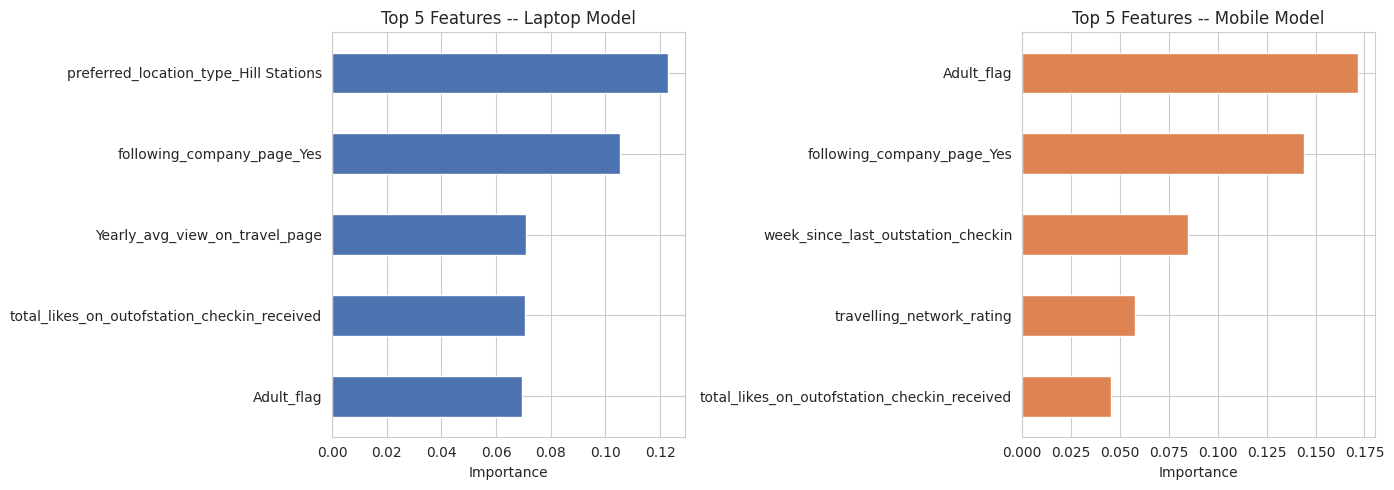

In [ ]:
# plot feature importances as a horizontal bar chart -- easier to read than a printed list
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Laptop feature importance chart
laptop_importances.head(5).sort_values().plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_title("Top 5 Features -- Laptop Model")
axes[0].set_xlabel("Importance")

# Mobile feature importance chart
mobile_importances.head(5).sort_values().plot(kind="barh", ax=axes[1], color="#DD8452")
axes[1].set_title("Top 5 Features -- Mobile Model")
axes[1].set_xlabel("Importance")

plt.tight_layout()
plt.savefig("feature_importance_grid.png", dpi=300, bbox_inches="tight")
plt.show()